In [ ]:
import zipfile

# Path to the zip file
zip_file_path = '/content/archive (2).zip'
# Directory where to extract
extract_to_dir = 'extracted_files/'

# Open the zip file
with zipfile.ZipFile(zip_file_path, 'r') as zip_ref:
    # Extract all contents to the specified directory
    zip_ref.extractall(extract_to_dir)

print(f"Files extracted to {extract_to_dir}")

Files extracted to extracted_files/


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [ ]:
d=pd.read_csv("/content/extracted_files/twitter_training.csv",   header=None,
                 names=["tweet_id", "entity", "sentiment", "text"])

d

,tweet_id,entity,sentiment,text
0,2401,Borderlands,Positive,im getting on borderlands and i will murder yo...
1,2401,Borderlands,Positive,I am coming to the borders and I will kill you...
2,2401,Borderlands,Positive,im getting on borderlands and i will kill you ...
3,2401,Borderlands,Positive,im coming on borderlands and i will murder you...
4,2401,Borderlands,Positive,im getting on borderlands 2 and i will murder ...
...,...,...,...,...
74677,9200,Nvidia,Positive,Just realized that the Windows partition of my...
74678,9200,Nvidia,Positive,Just realized that my Mac window partition is ...
74679,9200,Nvidia,Positive,Just realized the windows partition of my Mac ...
74680,9200,Nvidia,Positive,Just realized between the windows partition of...


In [ ]:
d.info()
print(d.columns.tolist())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 74682 entries, 0 to 74681
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   tweet_id   74682 non-null  int64 
 1   entity     74682 non-null  object
 2   sentiment  74682 non-null  object
 3   text       73996 non-null  object
dtypes: int64(1), object(3)
memory usage: 2.3+ MB
['tweet_id', 'entity', 'sentiment', 'text']


In [ ]:
print(d.isnull().sum())
d.duplicated().sum()

tweet_id       0
entity         0
sentiment      0
text         686
dtype: int64


np.int64(2700)

In [ ]:
d.drop_duplicates(inplace=True)
d.duplicated().sum()

np.int64(0)

In [ ]:
from sklearn.model_selection import train_test_split
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

valid = ["Negative", "Neutral", "Positive"]
d = d[d["sentiment"].isin(valid)]

sent_map = {"Negative":0, "Neutral":1, "Positive":2}
d["label"] = d["sentiment"].map(sent_map)

# Fill NaN values in the 'text' column with empty strings before splitting
d["text"] = d["text"].fillna('')

X_train, X_test, y_train, y_test = train_test_split(
    d["text"], d["label"], test_size=0.2, random_state=42
)

tokenizer = Tokenizer(num_words=20000, oov_token="<OOV>")
tokenizer.fit_on_texts(X_train)

X_train_seq = tokenizer.texts_to_sequences(X_train)
X_test_seq = tokenizer.texts_to_sequences(X_test)


max_len = 40
X_train_pad = pad_sequences(X_train_seq, maxlen=max_len, padding="post")
X_test_pad = pad_sequences(X_test_seq, maxlen=max_len, padding="post")

In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, Dense

model = Sequential([
    Embedding(input_dim=20000, output_dim=64, input_length=max_len),
    SimpleRNN(64, return_sequences=False),
    Dense(32, activation="relu"),
    #Dense(32, activation="relu"),

    Dense(3, activation="softmax")


])

model.compile(
    loss="sparse_categorical_crossentropy",
    optimizer="adam",
    metrics=["accuracy"]
)

# Explicitly build the model before printing the summary
model.build(input_shape=(None, max_len))
model.summary()

history = model.fit(
    X_train_pad, y_train,
    validation_split=0.20,
    epochs=5,
    batch_size=64
)

loss, acc = model.evaluate(X_test_pad, y_test)
print("Test Accuracy:", acc)

simple_rnn_model = model

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 40, 64)         │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,290,435 (4.92 MB)

 Trainable params: 1,290,435 (4.92 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
594/594 ━━━━━━━━━━━━━━━━━━━━ 20s 29ms/step - accuracy: 0.5829 - loss: 0.8823 - val_accuracy: 0.6975 - val_loss: 0.7134
Epoch 2/5
594/594 ━━━━━━━━━━━━━━━━━━━━ 18s 31ms/step - accuracy: 0.8245 - loss: 0.4513 - val_accuracy: 0.7959 - val_loss: 0.5102
Epoch 3/5
594/594 ━━━━━━━━━━━━━━━━━━━━ 17s 28ms/step - accuracy: 0.9108 - loss: 0.2397 - val_accuracy: 0.8090 - val_loss: 0.5159
Epoch 4/5
594/594 ━━━━━━━━━━━━━━━━━━━━ 17s 29ms/step - accuracy: 0.9365 - loss: 0.1630 - val_accuracy: 0.8239 - val_loss: 0.5061
Epoch 5/5
594/594 ━━━━━━━━━━━━━━━━━━━━ 19s 32ms/step - accuracy: 0.9494 - loss: 0.1277 - val_accuracy: 0.8145 - val_loss: 0.5300
372/372 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8129 - loss: 0.5491
Test Accuracy: 0.8128787875175476


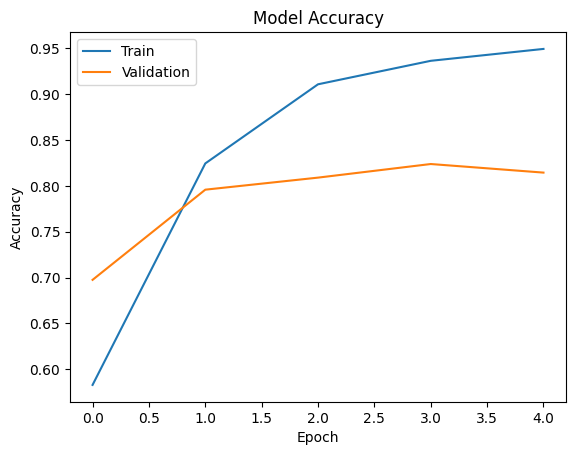

In [ ]:
import matplotlib.pyplot as plt
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')

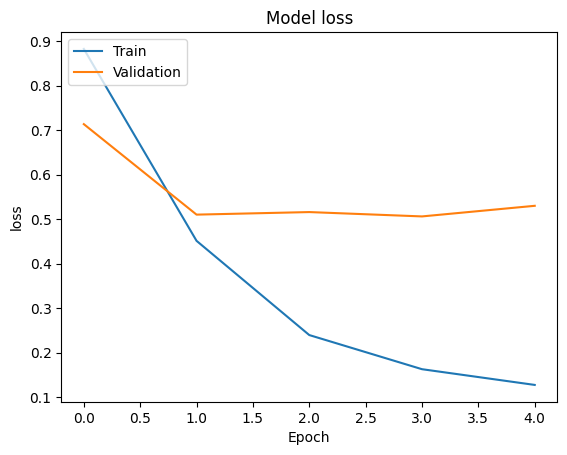

In [ ]:
import matplotlib.pyplot as plt
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model loss')
plt.ylabel('loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')

372/372 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step


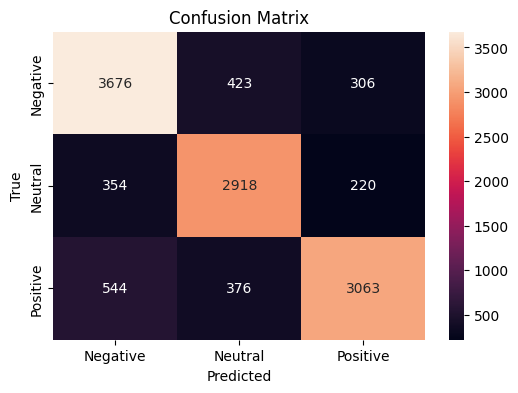

              precision    recall  f1-score   support

           0       0.80      0.83      0.82      4405
           1       0.79      0.84      0.81      3492
           2       0.85      0.77      0.81      3983

    accuracy                           0.81     11880
   macro avg       0.81      0.81      0.81     11880
weighted avg       0.81      0.81      0.81     11880



In [ ]:
from sklearn.metrics import confusion_matrix, classification_report

y_pred = model.predict(X_test_pad)
y_pred_labels = np.argmax(y_pred, axis=1)

cm = confusion_matrix(y_test, y_pred_labels)

plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt="d",
            xticklabels=["Negative","Neutral","Positive"],
            yticklabels=["Negative","Neutral","Positive"])
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix")
plt.show()

print(classification_report(y_test, y_pred_labels))

In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, Dense,LSTM

model = Sequential([
    Embedding(input_dim=20000, output_dim=64, input_length=max_len),
    LSTM(64, return_sequences=False),
    Dense(32, activation="relu"),
    Dense(3, activation="softmax")
])

model.compile(
    loss="sparse_categorical_crossentropy",
    optimizer="adam",
    metrics=["accuracy"]
)

# Explicitly build the model before printing the summary
model.build(input_shape=(None, max_len))
model.summary()

history = model.fit(
    X_train_pad, y_train,
    validation_split=0.2,
    epochs=5,
    batch_size=64
)

loss, acc = model.evaluate(X_test_pad, y_test)
print("Test Accuracy:", acc)

lstm_model = model

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 40, 64)         │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,315,203 (5.02 MB)

 Trainable params: 1,315,203 (5.02 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
594/594 ━━━━━━━━━━━━━━━━━━━━ 32s 50ms/step - accuracy: 0.6225 - loss: 0.8186 - val_accuracy: 0.7665 - val_loss: 0.5880
Epoch 2/5
594/594 ━━━━━━━━━━━━━━━━━━━━ 29s 48ms/step - accuracy: 0.8230 - loss: 0.4661 - val_accuracy: 0.8040 - val_loss: 0.5080
Epoch 3/5
594/594 ━━━━━━━━━━━━━━━━━━━━ 28s 48ms/step - accuracy: 0.8846 - loss: 0.3096 - val_accuracy: 0.8451 - val_loss: 0.4196
Epoch 4/5
594/594 ━━━━━━━━━━━━━━━━━━━━ 32s 54ms/step - accuracy: 0.9074 - loss: 0.2392 - val_accuracy: 0.8580 - val_loss: 0.3951
Epoch 5/5
594/594 ━━━━━━━━━━━━━━━━━━━━ 39s 51ms/step - accuracy: 0.9193 - loss: 0.2015 - val_accuracy: 0.8552 - val_loss: 0.4296
372/372 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - accuracy: 0.8518 - loss: 0.4390
Test Accuracy: 0.8517676591873169


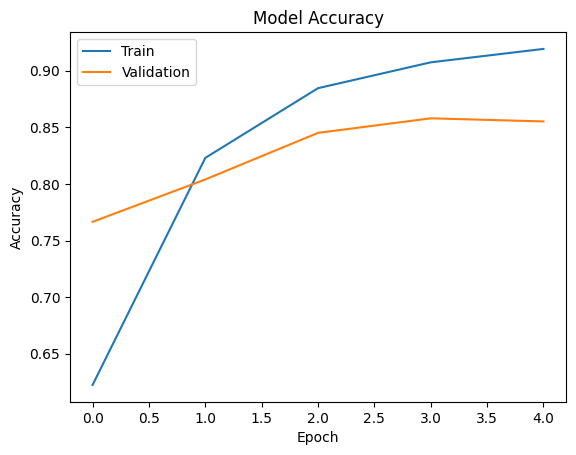

In [ ]:
import matplotlib.pyplot as plt
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')

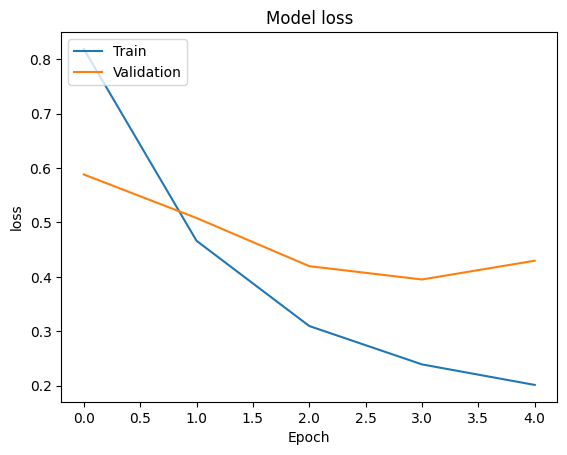

In [ ]:
import matplotlib.pyplot as plt
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model loss')
plt.ylabel('loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')

372/372 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step


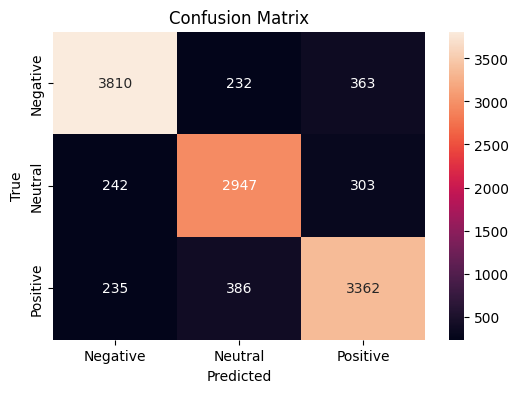

              precision    recall  f1-score   support

           0       0.89      0.86      0.88      4405
           1       0.83      0.84      0.84      3492
           2       0.83      0.84      0.84      3983

    accuracy                           0.85     11880
   macro avg       0.85      0.85      0.85     11880
weighted avg       0.85      0.85      0.85     11880



In [ ]:
from sklearn.metrics import confusion_matrix, classification_report

y_pred = model.predict(X_test_pad)
y_pred_labels = np.argmax(y_pred, axis=1)

cm = confusion_matrix(y_test, y_pred_labels)

plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt="d",
            xticklabels=["Negative","Neutral","Positive"],
            yticklabels=["Negative","Neutral","Positive"])
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix")
plt.show()

print(classification_report(y_test, y_pred_labels))

In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, Dense,LSTM,Bidirectional

model = Sequential([
    Embedding(input_dim=20000, output_dim=64, input_length=max_len),
    Bidirectional(LSTM(64, return_sequences=False)), # Fix: Wrap LSTM layer within Bidirectional
    Dense(32, activation="tanh"),
    Dense(3, activation="softmax")
])

model.compile(
    loss="sparse_categorical_crossentropy",
    optimizer="adam",
    metrics=["accuracy"]
)

# Explicitly build the model before printing the summary
model.build(input_shape=(None, max_len))
model.summary()

history = model.fit(
    X_train_pad, y_train,
    validation_split=0.2,
    epochs=5,
    batch_size=64
)

loss, acc = model.evaluate(X_test_pad, y_test)
print("Test Accuracy:", acc)

bilstm_model = model

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_4 (Embedding)         │ (None, 40, 64)         │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ (None, 128)            │        66,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,350,275 (5.15 MB)

 Trainable params: 1,350,275 (5.15 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
594/594 ━━━━━━━━━━━━━━━━━━━━ 53s 82ms/step - accuracy: 0.7066 - loss: 0.6834 - val_accuracy: 0.8102 - val_loss: 0.4824
Epoch 2/5
594/594 ━━━━━━━━━━━━━━━━━━━━ 83s 84ms/step - accuracy: 0.8776 - loss: 0.3130 - val_accuracy: 0.8651 - val_loss: 0.3590
Epoch 3/5
594/594 ━━━━━━━━━━━━━━━━━━━━ 77s 76ms/step - accuracy: 0.9214 - loss: 0.1959 - val_accuracy: 0.8791 - val_loss: 0.3339
Epoch 4/5
594/594 ━━━━━━━━━━━━━━━━━━━━ 46s 78ms/step - accuracy: 0.9392 - loss: 0.1481 - val_accuracy: 0.8858 - val_loss: 0.3439
Epoch 5/5
594/594 ━━━━━━━━━━━━━━━━━━━━ 80s 75ms/step - accuracy: 0.9488 - loss: 0.1245 - val_accuracy: 0.8826 - val_loss: 0.3808
372/372 ━━━━━━━━━━━━━━━━━━━━ 5s 15ms/step - accuracy: 0.8710 - loss: 0.3943
Test Accuracy: 0.8709595799446106


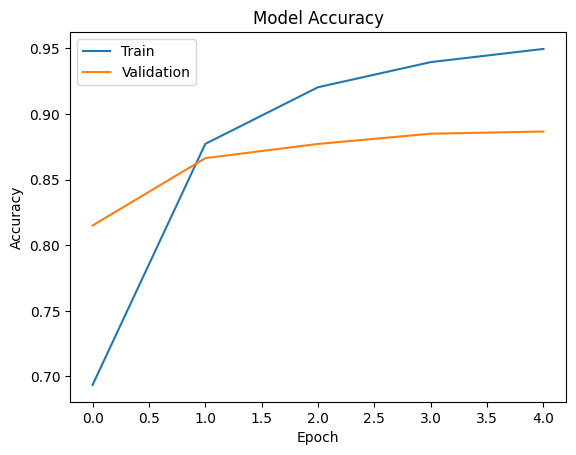

In [ ]:
import matplotlib.pyplot as plt
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')

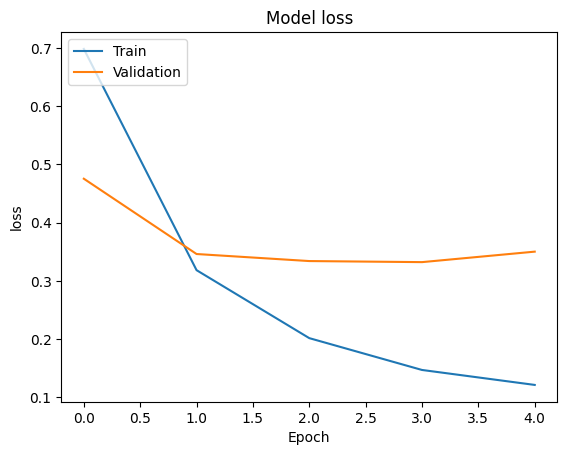

In [ ]:
import matplotlib.pyplot as plt
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model loss')
plt.ylabel('loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')

372/372 ━━━━━━━━━━━━━━━━━━━━ 6s 16ms/step


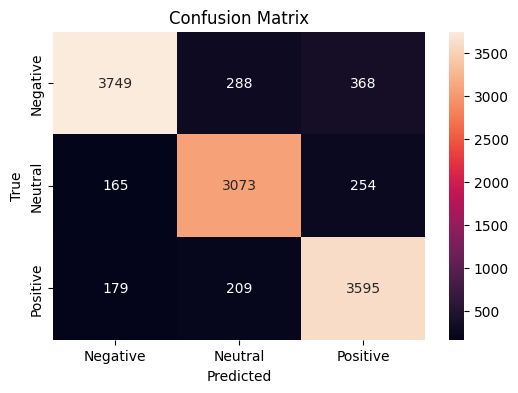

              precision    recall  f1-score   support

           0       0.92      0.85      0.88      4405
           1       0.86      0.88      0.87      3492
           2       0.85      0.90      0.88      3983

    accuracy                           0.88     11880
   macro avg       0.88      0.88      0.88     11880
weighted avg       0.88      0.88      0.88     11880



In [ ]:
from sklearn.metrics import confusion_matrix, classification_report

y_pred = model.predict(X_test_pad)
y_pred_labels = np.argmax(y_pred, axis=1)

cm = confusion_matrix(y_test, y_pred_labels)

plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt="d",
            xticklabels=["Negative","Neutral","Positive"],
            yticklabels=["Negative","Neutral","Positive"])
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix")
plt.show()

print(classification_report(y_test, y_pred_labels))

In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, Dense,LSTM,Bidirectional,GRU #GATE RECURRENT UNIT

model = Sequential([
    Embedding(input_dim=20000, output_dim=64, input_length=max_len),
    GRU(64, return_sequences=False),
    Dense(32, activation="relu"),
    Dense(3, activation="softmax")
])

model.compile(
    loss="sparse_categorical_crossentropy",
    optimizer="adam",
    metrics=["accuracy"]
)

# Explicitly build the model before printing the summary
model.build(input_shape=(None, max_len))
model.summary()

history = model.fit(
    X_train_pad, y_train,
    validation_split=0.2,
    epochs=5,
    batch_size=64
)

loss, acc = model.evaluate(X_test_pad, y_test)
print("Test Accuracy:", acc)

gru_model = model

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_3 (Embedding)         │ (None, 40, 64)         │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru (GRU)                       │ (None, 64)             │        24,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,307,139 (4.99 MB)

 Trainable params: 1,307,139 (4.99 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
594/594 ━━━━━━━━━━━━━━━━━━━━ 36s 55ms/step - accuracy: 0.5145 - loss: 0.9296 - val_accuracy: 0.7204 - val_loss: 0.6625
Epoch 2/5
594/594 ━━━━━━━━━━━━━━━━━━━━ 34s 57ms/step - accuracy: 0.8076 - loss: 0.4829 - val_accuracy: 0.8384 - val_loss: 0.4295
Epoch 3/5
594/594 ━━━━━━━━━━━━━━━━━━━━ 39s 54ms/step - accuracy: 0.8922 - loss: 0.2785 - val_accuracy: 0.8547 - val_loss: 0.3939
Epoch 4/5
594/594 ━━━━━━━━━━━━━━━━━━━━ 41s 54ms/step - accuracy: 0.9240 - loss: 0.1941 - val_accuracy: 0.8786 - val_loss: 0.3489
Epoch 5/5
594/594 ━━━━━━━━━━━━━━━━━━━━ 33s 55ms/step - accuracy: 0.9388 - loss: 0.1501 - val_accuracy: 0.8828 - val_loss: 0.3482
372/372 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.8688 - loss: 0.3748
Test Accuracy: 0.8687710165977478


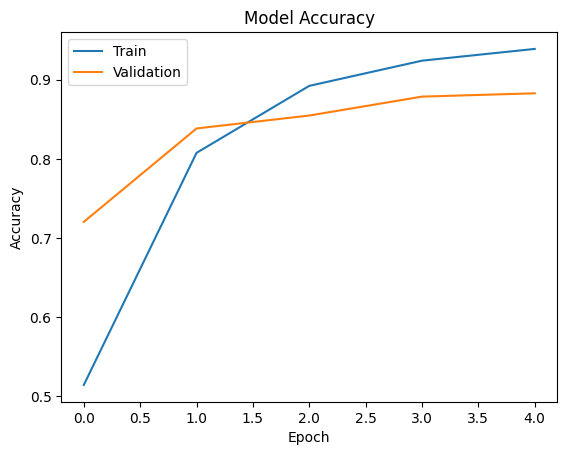

In [ ]:
import matplotlib.pyplot as plt
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')

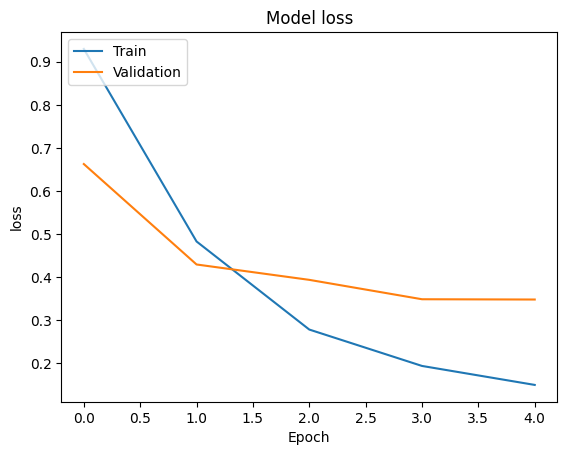

In [ ]:
import matplotlib.pyplot as plt
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model loss')
plt.ylabel('loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')

372/372 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step


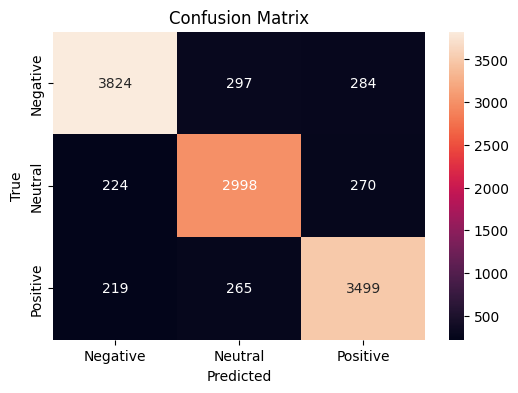

              precision    recall  f1-score   support

           0       0.90      0.87      0.88      4405
           1       0.84      0.86      0.85      3492
           2       0.86      0.88      0.87      3983

    accuracy                           0.87     11880
   macro avg       0.87      0.87      0.87     11880
weighted avg       0.87      0.87      0.87     11880



In [ ]:
from sklearn.metrics import confusion_matrix, classification_report

y_pred = model.predict(X_test_pad)
y_pred_labels = np.argmax(y_pred, axis=1)

cm = confusion_matrix(y_test, y_pred_labels)

plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt="d",
            xticklabels=["Negative","Neutral","Positive"],
            yticklabels=["Negative","Neutral","Positive"])
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix")
plt.show()

print(classification_report(y_test, y_pred_labels))

In [ ]:
text = ["I am very happy with this product"]

seq = tokenizer.texts_to_sequences(text)
pad = pad_sequences(seq, maxlen=max_len, padding='post')

pred = simple_rnn_model.predict(pad)

label_map = {0: "Negative", 1: "Neutral", 2: "Positive"}

print("Prediction:", label_map[np.argmax(pred)])
print("Probabilities:", pred)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
Prediction: Neutral
Probabilities: [[0.20937745 0.662467   0.12815557]]


In [ ]:
text = ["I am very happy with this product"]

seq = tokenizer.texts_to_sequences(text)
pad = pad_sequences(seq, maxlen=max_len, padding='post')

pred = bilstm_model.predict(pad)

label_map = {0: "Negative", 1: "Neutral", 2: "Positive"}

print("Prediction:", label_map[np.argmax(pred)])
print("Probabilities:", pred)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 360ms/step
Prediction: Positive
Probabilities: [[0.00396047 0.05879585 0.93724364]]


In [ ]:
text = ["I am very happy with this product"]

seq = tokenizer.texts_to_sequences(text)
pad = pad_sequences(seq, maxlen=max_len, padding='post')

pred = gru_model.predict(pad)

label_map = {0: "Negative", 1: "Neutral", 2: "Positive"}

print("Prediction:", label_map[np.argmax(pred)])
print("Probabilities:", pred)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step
Prediction: Positive
Probabilities: [[0.00517092 0.00317211 0.991657  ]]


In [ ]:
text = ["I am very happy with this product"]

seq = tokenizer.texts_to_sequences(text)
pad = pad_sequences(seq, maxlen=max_len, padding='post')

pred = lstm_model.predict(pad)

label_map = {0: "Negative", 1: "Neutral", 2: "Positive"}

print("Prediction:", label_map[np.argmax(pred)])
print("Probabilities:", pred)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
Prediction: Positive
Probabilities: [[0.01172457 0.01130905 0.97696644]]


In [ ]:
text = ["I really love this game, it is amazing"]

seq = tokenizer.texts_to_sequences(text)
pad = pad_sequences(seq, maxlen=max_len, padding='post')

pred = lstm_model.predict(pad)

label_map = {0: "Negative", 1: "Neutral", 2: "Positive"}

print("Prediction:", label_map[np.argmax(pred)])
print("Probabilities:", pred)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step
Prediction: Positive
Probabilities: [[0.00292096 0.00312292 0.99395615]]


In [ ]:
text = ["I really love this game, it is amazing"]

seq = tokenizer.texts_to_sequences(text)
pad = pad_sequences(seq, maxlen=max_len, padding='post')

pred = bilstm_model.predict(pad)

label_map = {0: "Negative", 1: "Neutral", 2: "Positive"}

print("Prediction:", label_map[np.argmax(pred)])
print("Probabilities:", pred)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step
Prediction: Positive
Probabilities: [[4.4229440e-04 1.9001632e-04 9.9936765e-01]]


In [ ]:
text = ["I really love this game, it is amazing"]

seq = tokenizer.texts_to_sequences(text)
pad = pad_sequences(seq, maxlen=max_len, padding='post')

pred = gru_model.predict(pad)

label_map = {0: "Negative", 1: "Neutral", 2: "Positive"}

print("Prediction:", label_map[np.argmax(pred)])
print("Probabilities:", pred)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step
Prediction: Positive
Probabilities: [[8.5104152e-04 5.4208742e-04 9.9860686e-01]]


In [ ]:
text = ["I really love this game, it is amazing"]

seq = tokenizer.texts_to_sequences(text)
pad = pad_sequences(seq, maxlen=max_len, padding='post')

pred = simple_rnn_model.predict(pad)

label_map = {0: "Negative", 1: "Neutral", 2: "Positive"}

print("Prediction:", label_map[np.argmax(pred)])
print("Probabilities:", pred)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 84ms/step
Prediction: Positive
Probabilities: [[0.12555116 0.11304162 0.76140726]]


In [ ]:
text = ["I really love this game, it is amazing"]

seq = tokenizer.texts_to_sequences(text)
pad = pad_sequences(seq, maxlen=max_len, padding='post')

pred = bilstm_model.predict(pad)

label_map = {0: "Negative", 1: "Neutral", 2: "Positive"}

print("Prediction:", label_map[np.argmax(pred)])
print("Probabilities:", pred)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
Prediction: Positive
Probabilities: [[5.3680025e-04 2.6984702e-04 9.9919337e-01]]
